# Training an image restorer (super-resolution + denoising) on Google Colab

This notebook trains a small neural network **from scratch** to turn blurry, noisy images into
clean ones. Everything runs online in Colab: the dataset downloads straight into Colab, nothing
goes onto your laptop except the finished model (a few MB).

- **Dataset:** DIV2K, high-quality 2K photos made for super-resolution research. We use its
  100-image validation set: 90 images for training, 10 kept aside for testing.
  Page: https://data.vision.ee.ethz.ch/cvl/DIV2K/
  (paper: Agustsson & Timofte, *NTIRE 2017 Challenge on Single Image Super-Resolution*, CVPR Workshops 2017)
- **Training pairs:** each clean photo is cut into small patches, and each patch is damaged on the
  fly (shrunk and enlarged again so it turns blurry, sometimes extra blur, plus random noise). The
  network learns to recover the clean patch. The damage is random every time, so it never sees
  the same pair twice.
- **Model:** TinyRestorer, about 290,000 parameters (7 residual blocks, 48 channels), starting from
  random weights.
- **Proof it learned:** PSNR and SSIM on the 10 unseen test images, damaged input vs your model.

**Fast by design:** the damage is made on the GPU, training uses half precision, and a time limit
stops training after 8 minutes at most.

**Start:** Runtime → Change runtime type → **T4 GPU** → Save, then Runtime → **Run all**.
Total time: about 5 to 10 minutes.

## 1. Settings

In [1]:
import io, json, os, platform, random, shutil, sys, time, zipfile, hashlib, urllib.request
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

DATASET_PAGE = "https://data.vision.ee.ethz.ch/cvl/DIV2K/"
DATA_URL = "https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip"
DATA_DIR = Path("/content/data") if Path("/content").exists() else Path("data")
ZIP_PATH = DATA_DIR / "DIV2K_valid_HR.zip"
ZIP_MD5 = "9fcdda83005c5e5997799b69f955ff88"

HAS_GPU = torch.cuda.is_available()
device = "cuda" if HAS_GPU else "cpu"

# Network size. BLOCKS must stay at 7 or fewer: the app processes big images in tiles with a
# 16-pixel overlap, and 7 blocks "see" exactly 16 pixels around each pixel (2 per block + 2).
CHANNELS, BLOCKS = (48, 7) if HAS_GPU else (32, 6)
ITERATIONS = 6000 if HAS_GPU else 1500   # training steps
TIME_LIMIT_MINUTES = 8                   # stops earlier if this is reached
BATCH_SIZE = 32                          # patches per step
PATCH_SIZE = 64                          # patch width/height in pixels
LEARNING_RATE = 1e-3
TEST_IMAGES = 10
EVAL_EVERY = 500
SEED = 42
OUTPUT_DIR = Path("restorer")            # zipped and downloaded at the end

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True
hardware = torch.cuda.get_device_name(0) if HAS_GPU else f"CPU ({platform.processor() or platform.machine()})"
print("Hardware:", hardware)
if not HAS_GPU:
    print("\nNo GPU! Choose Runtime > Change runtime type > T4 GPU, then Runtime > Run all. "
          "On a CPU this notebook uses a smaller model and is much slower.")

Hardware: CPU (x86_64)

No GPU! Choose Runtime > Change runtime type > T4 GPU, then Runtime > Run all. On a CPU this notebook uses a smaller model and is much slower.


## 2. Download DIV2K into Colab (100 images, about a minute)

In [2]:
def download(url, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    part = dest.with_suffix(".part")
    with urllib.request.urlopen(url, timeout=60) as response, open(part, "wb") as f:
        total = int(response.headers.get("Content-Length", 0))
        done, shown = 0, -1
        while chunk := response.read(1 << 20):
            f.write(chunk)
            done += len(chunk)
            percent = done * 100 // total if total else 0
            if percent != shown:
                print(f"\rDownloading: {done / 1e6:.0f} of {total / 1e6:.0f} MB ({percent}%)", end="")
                shown = percent
    part.replace(dest)
    print()

if ZIP_PATH.exists():
    print("Already downloaded:", ZIP_PATH)
else:
    download(DATA_URL, ZIP_PATH)

md5 = hashlib.md5()
with open(ZIP_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
        md5.update(chunk)
print("Checksum OK" if md5.hexdigest() == ZIP_MD5 else "Warning: checksum differs (the file may be incomplete).")

extract_dir = DATA_DIR / "DIV2K_valid_HR"
if not extract_dir.exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
paths = sorted(extract_dir.glob("*.png"))
print(len(paths), "images, e.g.", paths[0].name)

Downloading: 449 of 449 MB (100%)
Checksum OK
100 images, e.g. 0801.png


### Load the images

Each 2K photo is shrunk to half size (about 1000 px wide) so patches cover more of each scene.
The training images are kept in GPU memory for speed. The last 10 images are the test set.

/tmp/ipykernel_1947/2793493217.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  train_imgs = [torch.from_numpy(a).permute(2, 0, 1).contiguous().to(device) for a in train_np]  # uint8 (3,H,W)


90 training images, 10 test images, e.g. (678, 1020, 3)


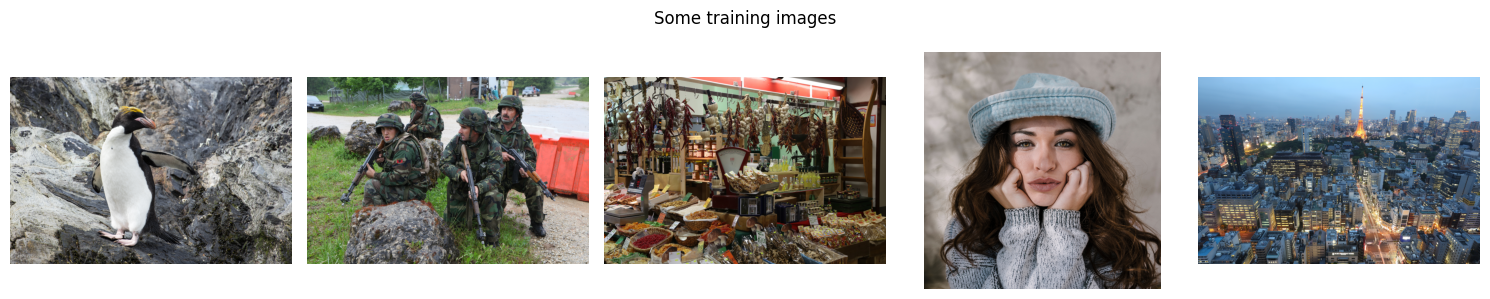

In [3]:
def load(path):
    return np.asarray(Image.open(path).convert("RGB").reduce(2))

train_np = [load(p) for p in paths[:-TEST_IMAGES]]
test_np = [load(p) for p in paths[-TEST_IMAGES:]]
train_imgs = [torch.from_numpy(a).permute(2, 0, 1).contiguous().to(device) for a in train_np]  # uint8 (3,H,W)
print(f"{len(train_np)} training images, {len(test_np)} test images, e.g. {train_np[0].shape}")

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, img in zip(axes, train_np[::18]):
    ax.imshow(img); ax.axis("off")
plt.suptitle("Some training images"); plt.tight_layout(); plt.show()

## 3. Damaging the images

This makes the "blurry and noisy" version of a clean image; the network's job is to undo it.
It's the same kind of damage the app's **Make it blurry and noisy** button creates, and the same
blur the app's **Upscale 2×** produces.

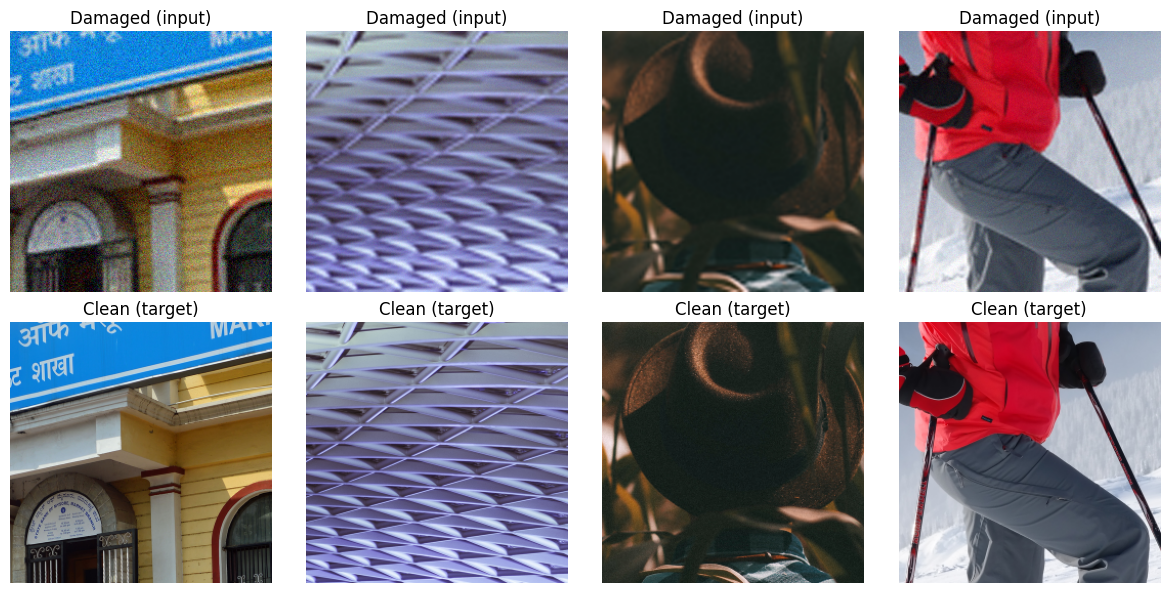

In [4]:
def gaussian_blur(img, sigma):
    r = 3
    x = torch.arange(-r, r + 1, dtype=torch.float32, device=img.device)
    k = torch.exp(-x ** 2 / (2 * sigma ** 2)); k = k / k.sum()
    kx = k.view(1, 1, 1, -1).repeat(3, 1, 1, 1)
    ky = k.view(1, 1, -1, 1).repeat(3, 1, 1, 1)
    img = F.conv2d(F.pad(img, (r, r, 0, 0), mode="reflect"), kx, groups=3)
    return F.conv2d(F.pad(img, (0, 0, r, r), mode="reflect"), ky, groups=3)

def degrade(clean, rng, generator=None):
    """clean: (N,3,H,W) floats 0..1. Returns damaged copies."""
    out = []
    for img in clean.split(1):
        _, _, h, w = img.shape
        s = rng.uniform(1.5, 3.0)                       # shrink and enlarge -> soft, low-res look
        small = F.interpolate(img, size=(max(1, round(h / s)), max(1, round(w / s))),
                              mode="bicubic", align_corners=False, antialias=True)
        img = F.interpolate(small, size=(h, w), mode="bicubic", align_corners=False)
        if rng.random() < 0.3:                          # sometimes extra blur
            img = gaussian_blur(img, rng.uniform(0.3, 1.0))
        if rng.random() < 0.7:                          # usually random noise
            noise = torch.randn(img.shape, generator=generator, device=img.device, dtype=img.dtype)
            img = img + noise * (rng.uniform(2, 20) / 255)
        out.append((img.clamp(0, 1) * 255).round() / 255)  # back to 8-bit levels, like a real file
    return torch.cat(out)

rng = random.Random(SEED)

def make_batch():
    patches = []
    for _ in range(BATCH_SIZE):
        img = train_imgs[rng.randrange(len(train_imgs))]
        _, h, w = img.shape
        top, left = rng.randrange(h - PATCH_SIZE + 1), rng.randrange(w - PATCH_SIZE + 1)
        p = img[:, top:top + PATCH_SIZE, left:left + PATCH_SIZE]
        if rng.random() < 0.5: p = p.flip(2)            # random flips/rotations = more variety
        if rng.random() < 0.5: p = p.flip(1)
        if rng.random() < 0.5: p = p.transpose(1, 2)
        patches.append(p)
    clean = torch.stack(patches).float().div(255)
    return degrade(clean, rng), clean

# Fixed test set: a 256x256 crop from the middle of each test image, damaged once with fixed seeds.
def center_crop(a, size=256):
    t, l = (a.shape[0] - size) // 2, (a.shape[1] - size) // 2
    return a[t:t + size, l:l + size]

test_clean_cpu = torch.from_numpy(np.stack([center_crop(a) for a in test_np])).permute(0, 3, 1, 2).float().div(255)
test_damaged_cpu = degrade(test_clean_cpu, random.Random(1234), torch.Generator().manual_seed(1234))
test_x, test_y = test_damaged_cpu.to(device), test_clean_cpu.to(device)

to_img = lambda t: t.clamp(0, 1).permute(1, 2, 0).cpu().numpy()
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axes[0, i].imshow(to_img(test_damaged_cpu[i])); axes[0, i].set_title("Damaged (input)")
    axes[1, i].imshow(to_img(test_clean_cpu[i])); axes[1, i].set_title("Clean (target)")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Measuring quality

- **PSNR** (peak signal-to-noise ratio, in dB): how close the pixels are to the clean image. Higher
  is better; +1 dB is a clearly visible improvement.
- **SSIM** (structural similarity, 0 to 1): how similar edges, textures and contrast look. Higher is better.

In [5]:
def psnr(a, b):
    mse = ((a - b) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-10)
    return (10 * torch.log10(1 / mse)).mean().item()

def ssim(a, b):
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    g = torch.exp(-(torch.arange(11, dtype=torch.float32) - 5) ** 2 / (2 * 1.5 ** 2))
    g = g / g.sum()
    window = (g[:, None] * g[None, :]).expand(3, 1, 11, 11).to(a)
    blur = lambda x: F.conv2d(x, window, groups=3)
    mu_a, mu_b = blur(a), blur(b)
    var_a, var_b = blur(a * a) - mu_a ** 2, blur(b * b) - mu_b ** 2
    cov = blur(a * b) - mu_a * mu_b
    s = ((2 * mu_a * mu_b + c1) * (2 * cov + c2)) / ((mu_a ** 2 + mu_b ** 2 + c1) * (var_a + var_b + c2))
    return s.mean().item()

before = {"psnr": round(psnr(test_x, test_y), 2), "ssim": round(ssim(test_x, test_y), 4)}
print("BEFORE (damaged input vs clean):", before)

BEFORE (damaged input vs clean): {'psnr': 24.35, 'ssim': 0.6352}


## 5. The model

Residual learning: the network only predicts the *correction* to add to the damaged image, which is
much easier for a small network than drawing the whole image. This is the same code the app uses
(`backend/services/restorer_net.py`).

In [6]:
import torch
from torch import nn


class ResidualBlock(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1),
        )

    def forward(self, x):
        return x + self.body(x)


class TinyRestorer(nn.Module):
    def __init__(self, channels: int = 32, blocks: int = 6):
        super().__init__()
        self.head = nn.Conv2d(3, channels, 3, padding=1)            # pixels -> features
        self.body = nn.Sequential(*[ResidualBlock(channels) for _ in range(blocks)])
        self.tail = nn.Conv2d(channels, 3, 3, padding=1)            # features -> correction

    def forward(self, x):
        # x: images with values 0..1, shape (batch, 3, height, width)
        return x + self.tail(self.body(self.head(x)))

model = TinyRestorer(CHANNELS, BLOCKS).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"TinyRestorer: {n_params:,} parameters, starting from random weights")

TinyRestorer: 112,739 parameters, starting from random weights


## 6. Train (a few minutes)

Each step: make 32 damaged/clean patch pairs, run the model, measure the error (L1 loss: the average
pixel difference), and adjust the weights to reduce it. Every 500 steps the test PSNR is printed so
you can watch it rise above the damaged input's.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=ITERATIONS, eta_min=LEARNING_RATE * 0.01)
loss_fn = torch.nn.L1Loss()
try:
    scaler = torch.amp.GradScaler("cuda", enabled=HAS_GPU)
except (AttributeError, TypeError):           # older PyTorch
    scaler = torch.cuda.amp.GradScaler(enabled=HAS_GPU)

def evaluate(m):
    m.eval()
    with torch.inference_mode():
        out = m(test_x).clamp(0, 1)
    m.train()
    return psnr(out, test_y), ssim(out, test_y)

log = {"step": [], "loss": [], "eval_step": [], "eval_psnr": []}
running, steps_done, start = 0.0, 0, time.time()
model.train()
for step in range(1, ITERATIONS + 1):
    x, y = make_batch()
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=HAS_GPU):
        out = model(x)
    loss = loss_fn(out.float(), y)
    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    scheduler.step()
    steps_done = step

    running += loss.item()
    if step % 25 == 0:
        log["step"].append(step); log["loss"].append(running / 25); running = 0.0
    out_of_time = time.time() - start > TIME_LIMIT_MINUTES * 60
    if step % EVAL_EVERY == 0 or step == ITERATIONS or out_of_time:
        test_psnr, _ = evaluate(model)
        log["eval_step"].append(step); log["eval_psnr"].append(test_psnr)
        elapsed = time.time() - start
        print(f"step {step:>5}/{ITERATIONS}  loss {loss.item():.4f}  "
              f"test PSNR {test_psnr:.2f} dB (input {before['psnr']:.2f})  "
              f"{elapsed / 60:.1f} min, about {elapsed / step * (ITERATIONS - step) / 60:.1f} min left")
    if out_of_time:
        print(f"Time limit reached at step {step}; stopping.")
        break

training_minutes = (time.time() - start) / 60
print(f"Done: {steps_done} steps in {training_minutes:.1f} minutes")

step   231/1500  loss 0.0262  test PSNR 26.27 dB (input 24.35)  8.1 min, about 44.5 min left
Time limit reached at step 231; stopping.
Done: 231 steps in 8.1 minutes


## 7. Training curves

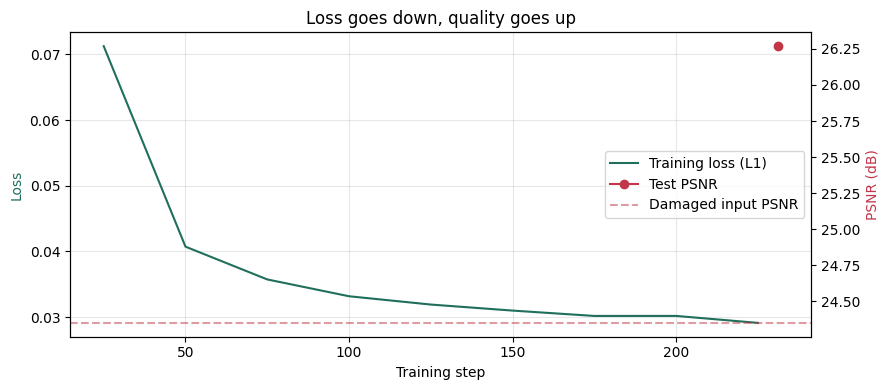

In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(log["step"], log["loss"], color="#1F6F5C", label="Training loss (L1)")
ax1.set_xlabel("Training step"); ax1.set_ylabel("Loss", color="#1F6F5C")
ax2 = ax1.twinx()
ax2.plot(log["eval_step"], log["eval_psnr"], "o-", color="#C2364A", label="Test PSNR")
ax2.axhline(before["psnr"], color="#C2364A", ls="--", alpha=.5, label="Damaged input PSNR")
ax2.set_ylabel("PSNR (dB)", color="#C2364A")
handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(handles, labels, loc="center right"); ax1.grid(alpha=.3)
plt.title("Loss goes down, quality goes up"); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=150); plt.show()

## 8. Results on the 10 unseen test images

             Damaged input    Your model    Change
PSNR (dB)            24.35         26.27     +1.92
SSIM                0.6352        0.7947   +0.1595


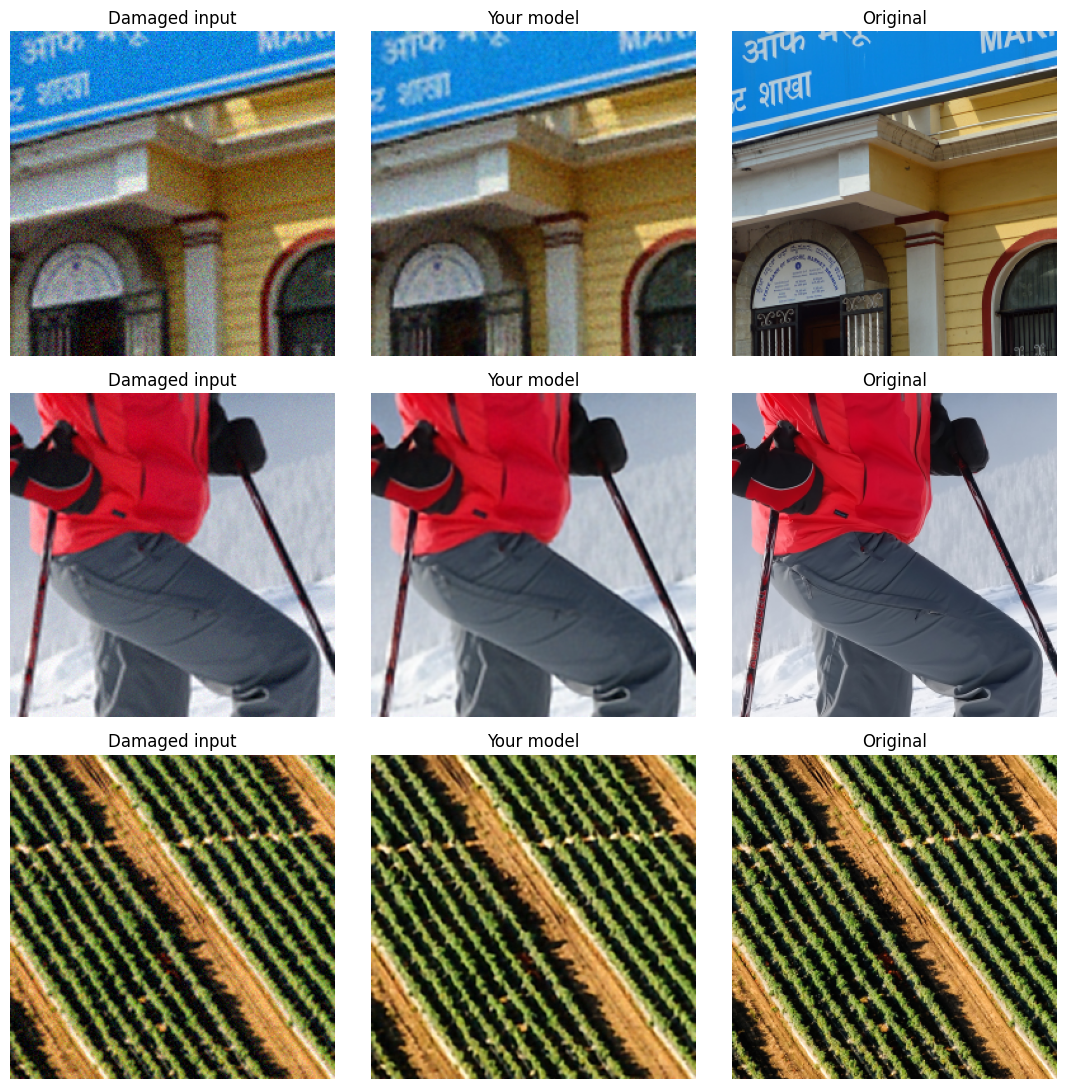

In [9]:
after_psnr, after_ssim = evaluate(model)
after = {"psnr": round(after_psnr, 2), "ssim": round(after_ssim, 4)}
print(f"{'':10}{'Damaged input':>16}{'Your model':>14}{'Change':>10}")
print(f"{'PSNR (dB)':10}{before['psnr']:>16.2f}{after['psnr']:>14.2f}{after['psnr'] - before['psnr']:>+10.2f}")
print(f"{'SSIM':10}{before['ssim']:>16.4f}{after['ssim']:>14.4f}{after['ssim'] - before['ssim']:>+10.4f}")

model.eval()
with torch.inference_mode():
    restored = model(test_x).clamp(0, 1).cpu()
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for row, i in enumerate([0, 3, 6]):
    for col, (img, title) in enumerate([(test_damaged_cpu[i], "Damaged input"),
                                        (restored[i], "Your model"),
                                        (test_clean_cpu[i], "Original")]):
        axes[row, col].imshow(to_img(img)); axes[row, col].set_title(title); axes[row, col].axis("off")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "examples.png", dpi=110); plt.show()

### Try it on your own image (optional)

Set `TRY_MY_IMAGE = True` and run this cell; Colab asks you to choose an image file.

In [10]:
TRY_MY_IMAGE = False
if TRY_MY_IMAGE:
    from google.colab import files
    name = next(iter(files.upload()))
    img = Image.open(name).convert("RGB")
    img.thumbnail((800, 800))
    x = torch.from_numpy(np.asarray(img)).permute(2, 0, 1).float().div(255).unsqueeze(0).to(device)
    with torch.inference_mode():
        y = model(x).clamp(0, 1)[0]
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    axes[0].imshow(img); axes[0].set_title("Input"); axes[1].imshow(to_img(y)); axes[1].set_title("Your model")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

## 9. Save the model and download it

This creates `restorer.zip` and downloads it. Unzip it into
`C:\Users\<you>\GenAI-Studio-models\restorer\` so that `restorer.pt` sits directly inside that
folder, then refresh the app page.

In [11]:
torch.save({k: v.float().cpu() for k, v in model.state_dict().items()}, OUTPUT_DIR / "restorer.pt")
(OUTPUT_DIR / "config.json").write_text(json.dumps({"channels": CHANNELS, "blocks": BLOCKS}))

report = {
    "dataset": {"name": "DIV2K (validation HR set)", "url": DATASET_PAGE, "download": DATA_URL,
                "train_images": len(train_np), "test_images": len(test_np)},
    "model": {"architecture": f"TinyRestorer ({BLOCKS} residual blocks, {CHANNELS} channels)",
              "parameters": n_params, "initialization": "random (trained from scratch)"},
    "hyperparameters": {"iterations": steps_done, "batch_size": BATCH_SIZE, "patch_size": PATCH_SIZE,
                        "learning_rate": LEARNING_RATE, "loss": "L1",
                        "optimizer": "Adam, cosine schedule, mixed precision"},
    "degradations": "bicubic down/up-scaling x1.5-3, optional Gaussian blur, Gaussian noise (sigma 2-20)",
    "hardware": hardware,
    "training_minutes": round(training_minutes, 1),
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "before": before,
    "after": after,
}
(OUTPUT_DIR / "training_report.json").write_text(json.dumps(report, indent=2))
print("Saved:", sorted(p.name for p in OUTPUT_DIR.iterdir()))

archive = shutil.make_archive("restorer", "zip", OUTPUT_DIR)
print("Created", archive, f"({os.path.getsize(archive) / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(archive)
except Exception:
    print("Download restorer.zip from the file browser on the left.")

Saved: ['config.json', 'examples.png', 'loss_curve.png', 'restorer.pt', 'training_report.json']
Created /content/restorer.zip (2.8 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>